# Ramen on DomainNet: the baseline for the true-label cache experiment

**Question.** How well does Ramen do on DomainNet, per domain and across seeds? This notebook fixes the baseline and
the noise floor that the true-label cache oracle is compared against.

**The experiment this folder builds up to.** Ramen files every test image into the memory queue of its *zero-shot
prediction*, so every zero-shot error lands in the wrong class queue. The oracle `true_label` files each image under
its **true label** instead (it uses ground truth, so it is an upper bound, not a method). Everything else (stored
gradient, retrieval, weighting, step, reset) stays Ramen's. This notebook only covers the baseline.

**Runs in this notebook.**

| Run name | What it is | Uses true labels? |
|---|---|---|
| `NoAdapt` | CLIP zero-shot, no adaptation | no |
| `Ramen` | Ramen (cfg/DomainNet/Ramen.yaml: capacity 300 per class, top-k 10, β 5, signSGD lr 0.01) | no |

**Data.** DomainNet, 6 domains (clipart, infograph, painting, quickdraw, real, sketch), 345 classes, 596,006 images,
mixed into one shuffled stream with batch size 100. Model: CLIP ViT-B/32, default 7-template prompt ensemble.

**Seeds.** A seed sets the stream order (which images arrive together and in what order). NoAdapt is identical for every seed.
Seed 0 is used for the per-domain analysis; seeds 0–4 of Ramen give the noise floor.

**How the runs were produced.** `exp.run(...)` in `new_experiments/ramen_analysis.py` through
`true_label_cache.TrueLabelCacheExperiment` (this folder), with the settings in its `DATASETS` (num_workers changes the stream order, so keep it).
Results are cached in `new_experiments/results/DomainNet_<model>_mixed_nall_bs100_s<seed>_<run>.pkl`.
A missing run is computed on the GPU. Use `python run_true_label.py DomainNet <seed>` for a detached run.

**What counts as a result.** A later variant's gain over Ramen counts only if it is above the **noise floor** = 2 × (max − min)
of Ramen's domain-averaged accuracy over seeds 0–4 (computed in section 4).

**How to read this notebook.** 1 Setup · 2 The data · 3 Sanity check of the new method · 4 Ramen results (per domain, over the stream, across seeds) ·
5 Interpretation · 6 Glossary. Accuracy is **domain-averaged** (mean of the per-domain accuracies) unless a table says *pooled*.

## 1. Setup

In [1]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')  # only used if a run is not cached

import matplotlib.pyplot as plt
import pandas as pd
from true_label_cache import TrueLabelCacheExperiment, seed_table, noise_floor, domain_avg

pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

DATASET, SEED, BY = 'DomainNet', 0, 'domain'
exp = TrueLabelCacheExperiment(DATASET, seed=SEED).run_all(('NoAdapt', 'Ramen'))

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt.pkl


Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_Ramen.pkl


## 2. The data the code ran on

Images and classes per domain, and how many the zero-shot model already gets right. These counts are the denominators
for everything below. Domains differ a lot in size: quickdraw and real are 29% each of the stream, clipart 8%.

In [2]:
exp.data_table()

,images,classes,NoAdapt correct
domain,,,
clipart,48833,345,"33,328 of 48,833 (68.2%)"
infograph,53201,345,"23,354 of 53,201 (43.9%)"
painting,75759,345,"48,924 of 75,759 (64.6%)"
quickdraw,172500,345,"22,992 of 172,500 (13.3%)"
real,175327,345,"143,982 of 175,327 (82.1%)"
sketch,70386,345,"42,265 of 70,386 (60.0%)"
all,596006,345,"314,845 of 596,006 (52.8%)"


## 3. Sanity check of the new method

`RamenTrueLabel` (src/methods/RamenTrueLabel.py) has a switch `filing`. With `filing: zero_shot` it must be Ramen
exactly, or any later comparison would measure a bug. The smoke test (`python run_true_label.py DomainNet 0 --smoke <dir>`,
200 images per domain = 1,200 images, seed 0:

- `zero_shot_filing` == `Ramen` on 1,200 of 1,200 images (100.00%)
- `true_label` == `RamenOracle` with `oracle: file_true` (the earlier implementation, 2026-10-23_cache_contamination)
  on 1,200 of 1,200 images (100.00%)

So the new class is Ramen when switched off, and it reproduces the earlier true-label oracle when switched on.

## 4. Ramen results

### 4a. Seed 0, overall

In [3]:
exp.summary_table(baseline='NoAdapt')

,correct,acc (domain avg),vs NoAdapt (pts),vs NoAdapt (images),fixed vs NoAdapt,broken vs NoAdapt,same pred as NoAdapt
NoAdapt,"314,845 of 596,006 (52.8%)",55.37,+0.00,+0,"0 of 596,006 (0.0%)","0 of 596,006 (0.0%)",100.00%
Ramen,"324,966 of 596,006 (54.5%)",56.8,+1.43,"+10,121","20,419 of 596,006 (3.4%)","10,298 of 596,006 (1.7%)",78.23%


*fixed* = NoAdapt wrong and Ramen right; *broken* = NoAdapt right and Ramen wrong. Net gain = fixed − broken.
Pooled accuracy (all images weighted equally) is lower than the domain average because quickdraw, the
hardest domain, is the largest.

In [4]:
print(f"pooled accuracy: NoAdapt {exp.results['NoAdapt'].correct.mean():.2%}, Ramen {exp.results['Ramen'].correct.mean():.2%}")

pooled accuracy: NoAdapt 52.83%, Ramen 54.52%


### 4b. Seed 0, per domain

In [5]:
exp.change_table('Ramen', 'NoAdapt', by=BY)

,NoAdapt,Ramen,images,fixed,broken,net (images),share of net gain
domain,,,,,,,
clipart,68.25,69.33,48833,1565,1037,528,5.2%
infograph,43.90,44.98,53201,1448,871,577,5.7%
painting,64.58,65.70,75759,2193,1346,847,8.4%
quickdraw,13.33,17.54,172500,10520,3256,7264,71.8%
real,82.12,82.27,175327,2560,2298,262,2.6%
sketch,60.05,60.96,70386,2133,1490,643,6.4%
domain avg,55.37,56.80,<NA>,<NA>,<NA>,<NA>,NaN


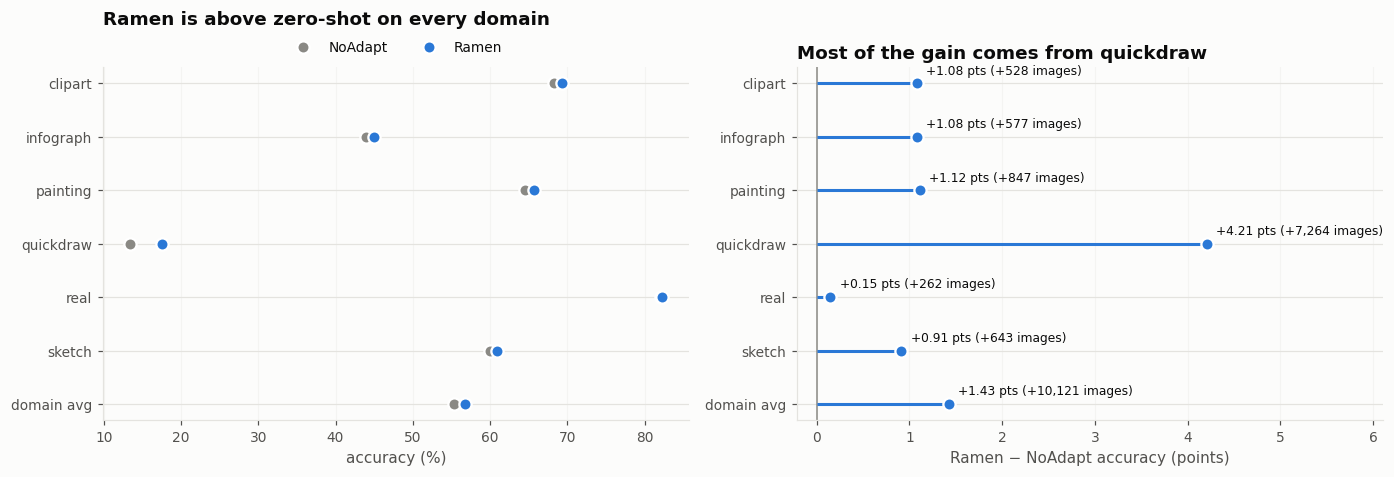

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 0.32 * len(exp.change_table('Ramen', by=BY)) + 2.2))
exp.plot_accuracy(['NoAdapt', 'Ramen'], by=BY, ax=axes[0])
axes[0].set_title('Ramen is above zero-shot on every domain', loc='left', pad=28)
exp.plot_gain('Ramen', 'NoAdapt', by=BY, ax=axes[1])
axes[1].set_title('Most of the gain comes from quickdraw', loc='left')
fig.tight_layout()

### 4c. Seed 0, over the stream

The gain over zero-shot along the stream (rolling window of 10,000 images, pooled over domains).

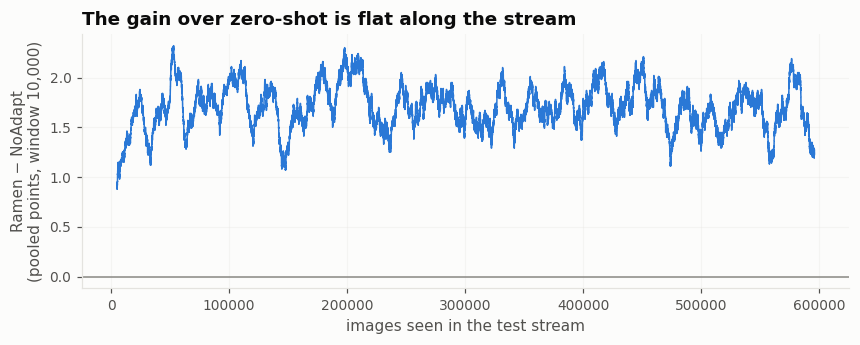

In [7]:
ax = exp.plot_stream_gain('Ramen', 'NoAdapt', window=10000)
ax.set_title('The gain over zero-shot is flat along the stream', loc='left');

### 4d. Seeds 0–4: the noise floor

Ramen's domain-averaged accuracy for each seed (the stream order changes, the data and model do not).

In [8]:
seeds = seed_table(DATASET, names=('Ramen',))
floor = noise_floor(seeds['Ramen'])
print(f"Ramen over seeds 0-4: {seeds['Ramen'].mean():.2f} ± {seeds['Ramen'].std():.2f}, "
      f"range {seeds['Ramen'].max() - seeds['Ramen'].min():.3f} pts -> noise floor = 2 x range = {floor:.2f} pts")
noadapt = domain_avg(exp.results['NoAdapt'])
seeds.assign(**{'vs NoAdapt (pts)': (seeds['Ramen'] - noadapt).round(2)}).round(2)

Ramen over seeds 0-4: 56.81 ± 0.02, range 0.055 pts -> noise floor = 2 x range = 0.11 pts


,Ramen,vs NoAdapt (pts)
seed,,
0,56.80,1.43
1,56.79,1.42
2,56.83,1.46
3,56.81,1.44
4,56.85,1.48


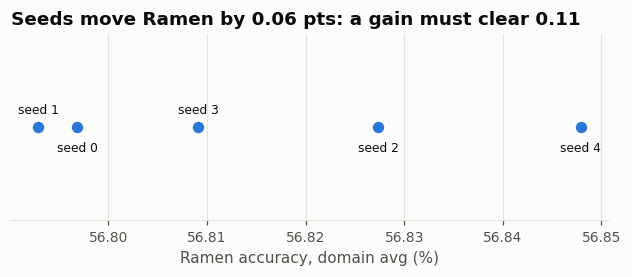

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.2))
ax.plot(seeds['Ramen'], [0] * len(seeds), 'o', ms=9, color='#2a78d6', mec='white', mew=1.5)
for s, v in seeds['Ramen'].items():
    ax.annotate(f'seed {s}', (v, 0), xytext=(0, 9 if s % 2 else -16), textcoords='offset points', ha='center', fontsize=8)
ax.set_yticks([]); ax.spines['left'].set_visible(False)
ax.set_xlabel('Ramen accuracy, domain avg (%)')
ax.set_title(f'Seeds move Ramen by {seeds.Ramen.max() - seeds.Ramen.min():.2f} pts: a gain must clear {floor:.2f}', loc='left');

## 5. Interpretation

- **Ramen beats zero-shot by +1.43 points** (55.37 → 56.80, domain-averaged, seed 0). That is +10,121 images
  (pooled 52.83% → 54.52%). Ramen changes 21.8% of predictions to reach this: 20,419 images fixed against 10,298 broken.
  Most of what Ramen changes is wrong → wrong, and about one change in three that matters is a break.
- **The gain is concentrated in quickdraw**: +4.21 points, net +7,264 images, 72% of the total net gain. The other five
  domains gain +0.15 (real) to +1.12 (painting). Real is almost a wash (2,560 fixed, 2,298 broken).
- **Seed-to-seed variation is tiny**: 56.79–56.85 over seeds 0–4, so the **noise floor is 0.11 points**. A true-label
  filing gain smaller than 0.11 on DomainNet is not distinguishable from changing the stream order.
- **What to expect next.** `RamenOracle file_true` (the same oracle, 2026-10-23) gave **−1.50** vs Ramen on seed 0
  (quickdraw −6.49). The next step reruns it with `RamenTrueLabel` and looks at why pure queues hurt.
  The class keeps per-batch logs for that (`zs_wrong`, `nonempty_queues`). One candidate is the stored gradient: it still
  sharpens the zero-shot prediction, so a pure queue of class c holds gradients that pull toward *other* classes
  whenever zero-shot was wrong.
- Caveat: per-domain numbers are seed 0 only.

## 6. Glossary

| Term | Meaning |
|---|---|
| NoAdapt | CLIP zero-shot classifier, no test-time adaptation |
| Ramen | Test-time adaptation with a per-class memory of (feature, own entropy gradient, entropy). Each image takes one signSGD step on gradients retrieved from the memory, predicts, and the weights are reset |
| queue / filing | Ramen's memory is one fixed-size queue per class; *filing* = choosing which queue a new image is written to (zero-shot prediction in Ramen) |
| true-label filing (`true_label`) | Oracle: file each image under its true class. Uses ground truth, so it is an upper bound, not a method |
| `zero_shot_filing` | `RamenTrueLabel` with filing by zero-shot prediction, which must equal Ramen (sanity check) |
| domain | A part of the stream with one kind of shift: a DomainNet domain, an ImageNet-C corruption; EuroSAT has one |
| domain-averaged accuracy | Mean of the per-domain accuracies (headline convention) |
| pooled accuracy | Correct images / all images |
| fixed / broken | Image wrong under NoAdapt and right under the run / right under NoAdapt and wrong under the run |
| seed | Sets the stream order; NoAdapt does not depend on it |
| noise floor | 2 × (max − min) of the baseline's accuracy over seeds 0–4; a gain must exceed it to count |
| mixed stream | All domains shuffled together into one test stream |